# Proyecto Final de Aprendizaje de Máquina
## Predicción de aprobación de crédito con árboles de decisión

**Autor:** Javier Alejandro Zúñiga Salvador
**Materia:** Aprendizaje de Máquina

---

## 1. Introducción

Cada vez que alguien pide una tarjeta de crédito, un banco tiene que decidir si se la aprueba o no. Si aprueba a una persona que luego no paga, pierde dinero. Si rechaza a una persona que sí hubiera pagado, pierde un cliente. Hacer esta revisión a mano para miles de solicitudes es lento, costoso y, además, depende mucho del criterio de cada analista. Por eso este problema es un caso clásico donde el aprendizaje de máquina ayuda: a partir de solicitudes pasadas ya resueltas se puede aprender un criterio consistente y rápido para apoyar la decisión [1].

**Problema a resolver:** predecir si una solicitud de tarjeta de crédito fue aprobada (`+`) o rechazada (`-`) a partir de las características del solicitante. Es un problema de **clasificación binaria supervisada**.

**Por qué nos interesan los árboles de decisión:** en el contexto financiero no basta con acertar, también hay que poder explicar por qué se tomó una decisión (un cliente rechazado tiene derecho a preguntar el motivo). Los árboles de decisión generan reglas del tipo si... entonces... que cualquier persona puede leer, así que son un buen punto de partida [2]. Además los comparamos con un Random Forest [3] para ver si vale la pena sacrificar interpretabilidad por rendimiento.

**Dataset:** *Credit Approval* del repositorio UCI [1]. Tiene 690 solicitudes y 15 variables (`A1` a `A15`). Los nombres y valores de las variables fueron anonimizados por confidencialidad, así que no sabemos qué significa cada columna en la vida real. Hay mezcla de variables numéricas y categóricas, y algunos valores faltantes.

**Resumen de la metodología** (cada punto corresponde a una sección de la notebook):

| Sección | Contenido |
|---|---|
| 2 | Carga de datos y análisis exploratorio (EDA) |
| 3 | Feature extraction y feature selection (filtro con información mutua) |
| 4 | Pipelines de scikit-learn (imputación, codificación, selección y modelo) |
| 5 | Optimización de hiperparámetros con repeated k-fold CV, gráfica de validación y curva de aprendizaje |
| 6 | Comparación estadística entre árbol de decisión y Random Forest (test de Wilcoxon) |
| 7 | Evaluación final sobre el conjunto de prueba |
| 8 | Visualización del espacio de características con t-SNE |
| 9 | Conclusiones |
| 10 | Referencias (IEEE) |

In [ ]:
!pip install -q ucimlrepo

In [2]:
import warnings
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from scipy import stats

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RepeatedStratifiedKFold, GridSearchCV,
                                     cross_val_score, validation_curve,
                                     learning_curve)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.manifold import TSNE
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay)

warnings.filterwarnings("ignore")

# Semilla fija para que los resultados sean reproducibles
SEED = 42
np.random.seed(SEED)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["figure.dpi"] = 100

## 2. Carga de datos y análisis exploratorio (EDA)

Descargamos el dataset directamente desde el repositorio de UCI con la librería `ucimlrepo`. La variable objetivo es `A16`, donde `+` significa solicitud aprobada y `-` rechazada. La convertimos a 1 y 0 para trabajar más cómodo.

In [3]:
# Descarga del dataset (id = 27 corresponde a Credit Approval)
credit = fetch_ucirepo(id=27)

X = credit.data.features.copy()
y_raw = credit.data.targets["A16"].copy()

# Aprobado (+) = 1, rechazado (-) = 0
y = (y_raw == "+").astype(int)
y.name = "aprobado"

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)
X.head()

Dimensiones de X: (690, 15)
Dimensiones de y: (690,)


,A15,A14,A13,A12,A11,A10,A9,A8,A7,A6,A5,A4,A3,A2,A1
0,0,202.0,g,f,1,t,t,1.25,v,w,g,u,0.000,30.83,b
1,560,43.0,g,f,6,t,t,3.04,h,q,g,u,4.460,58.67,a
2,824,280.0,g,f,0,f,t,1.50,h,q,g,u,0.500,24.50,a
3,3,100.0,g,t,5,t,t,3.75,v,w,g,u,1.540,27.83,b
4,0,120.0,s,f,0,f,t,1.71,v,w,g,u,5.625,20.17,b


In [4]:
# Los tipos de variable los definimos nosotros a partir de la descripción del dataset.
# A11 y A15 son enteros pero se comportan como conteos/montos, así que van como numéricas.
cols_num = ["A2", "A3", "A8", "A11", "A14", "A15"]
cols_cat = ["A1", "A4", "A5", "A6", "A7", "A9", "A10", "A12", "A13"]

# Aseguramos que las categóricas sean de tipo object (así funciona igual en cualquier versión de pandas)
X[cols_cat] = X[cols_cat].astype(object)

print("Numéricas  :", cols_num)
print("Categóricas:", cols_cat)
print("\nFilas duplicadas:", X.duplicated().sum())
X.describe().T

Numéricas  : ['A2', 'A3', 'A8', 'A11', 'A14', 'A15']
Categóricas: ['A1', 'A4', 'A5', 'A6', 'A7', 'A9', 'A10', 'A12', 'A13']

Filas duplicadas: 0


,count,mean,std,min,25%,50%,75%,max
A15,690.0,1017.385507,5210.102598,0.00,0.0000,5.00,395.5000,100000.00
A14,677.0,184.014771,173.806768,0.00,75.0000,160.00,276.0000,2000.00
A11,690.0,2.400000,4.862940,0.00,0.0000,0.00,3.0000,67.00
A8,690.0,2.223406,3.346513,0.00,0.1650,1.00,2.6250,28.50
A3,690.0,4.758725,4.978163,0.00,1.0000,2.75,7.2075,28.00
A2,678.0,31.568171,11.957862,13.75,22.6025,28.46,38.2300,80.25


### 2.1 Balance de clases

Lo primero que revisamos es si las clases están balanceadas, porque eso define qué métricas tiene sentido usar y si hace falta algún tratamiento especial.

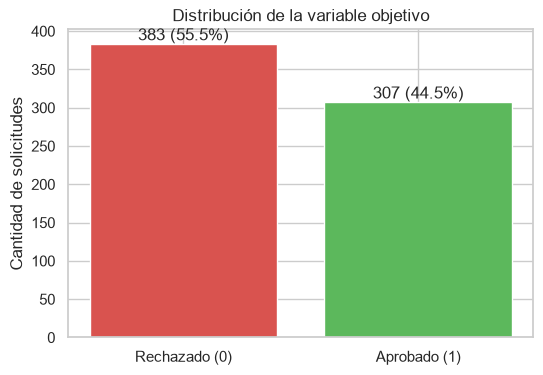

In [5]:
conteo = y.value_counts().sort_index()
porcentaje = y.value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(["Rechazado (0)", "Aprobado (1)"], conteo.values, color=["#d9534f", "#5cb85c"])
for b, n, p in zip(barras, conteo.values, porcentaje.values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 5, f"{n} ({p:.1f}%)", ha="center")
ax.set_title("Distribución de la variable objetivo")
ax.set_ylabel("Cantidad de solicitudes")
plt.show()

Las clases están bastante parejas (aproximadamente 55 % rechazadas y 45 % aprobadas), por lo que no hace falta aplicar técnicas de balanceo y la exactitud (*accuracy*) es una métrica razonable. Aun así vamos a reportar también precisión, recall, F1 y AUC-ROC. Además, un clasificador que siempre responda la clase mayoritaria acertaría cerca del 55 %, y ese es el piso que cualquier modelo debe superar.

### 2.2 Valores faltantes

En el dataset original los faltantes vienen marcados con el símbolo `?`. `ucimlrepo` los entrega como `NaN`.

,faltantes,porcentaje
A14,13,1.88
A2,12,1.74
A1,12,1.74
A6,9,1.30
A7,9,1.30
A4,6,0.87
A5,6,0.87



Filas con al menos un faltante: 37 de 690 (5.4%)


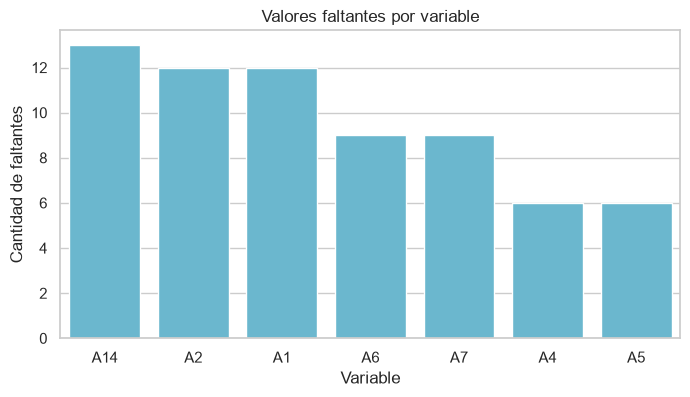

In [6]:
faltantes = X.isna().sum()
faltantes = faltantes[faltantes > 0].sort_values(ascending=False)

resumen_falt = pd.DataFrame({"faltantes": faltantes,
                             "porcentaje": (faltantes / len(X) * 100).round(2)})
display(resumen_falt)

print(f"\nFilas con al menos un faltante: {X.isna().any(axis=1).sum()} de {len(X)} "
      f"({X.isna().any(axis=1).mean() * 100:.1f}%)")

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=faltantes.index, y=faltantes.values, color="#5bc0de", ax=ax)
ax.set_title("Valores faltantes por variable")
ax.set_ylabel("Cantidad de faltantes")
ax.set_xlabel("Variable")
plt.show()

Hay 7 variables con faltantes, todos menores al 2 % por columna, pero en total afectan a cerca del 5 % de las filas. Con un dataset tan pequeño (690 filas) borrar esas filas sería un desperdicio, así que vamos a **imputar** dentro del pipeline (mediana para numéricas y moda para categóricas). Es importante hacerlo dentro del pipeline y no antes del split, porque así la mediana y la moda se calculan solo con los datos de entrenamiento y evitamos fuga de información (*data leakage*).

### 2.3 Variables numéricas

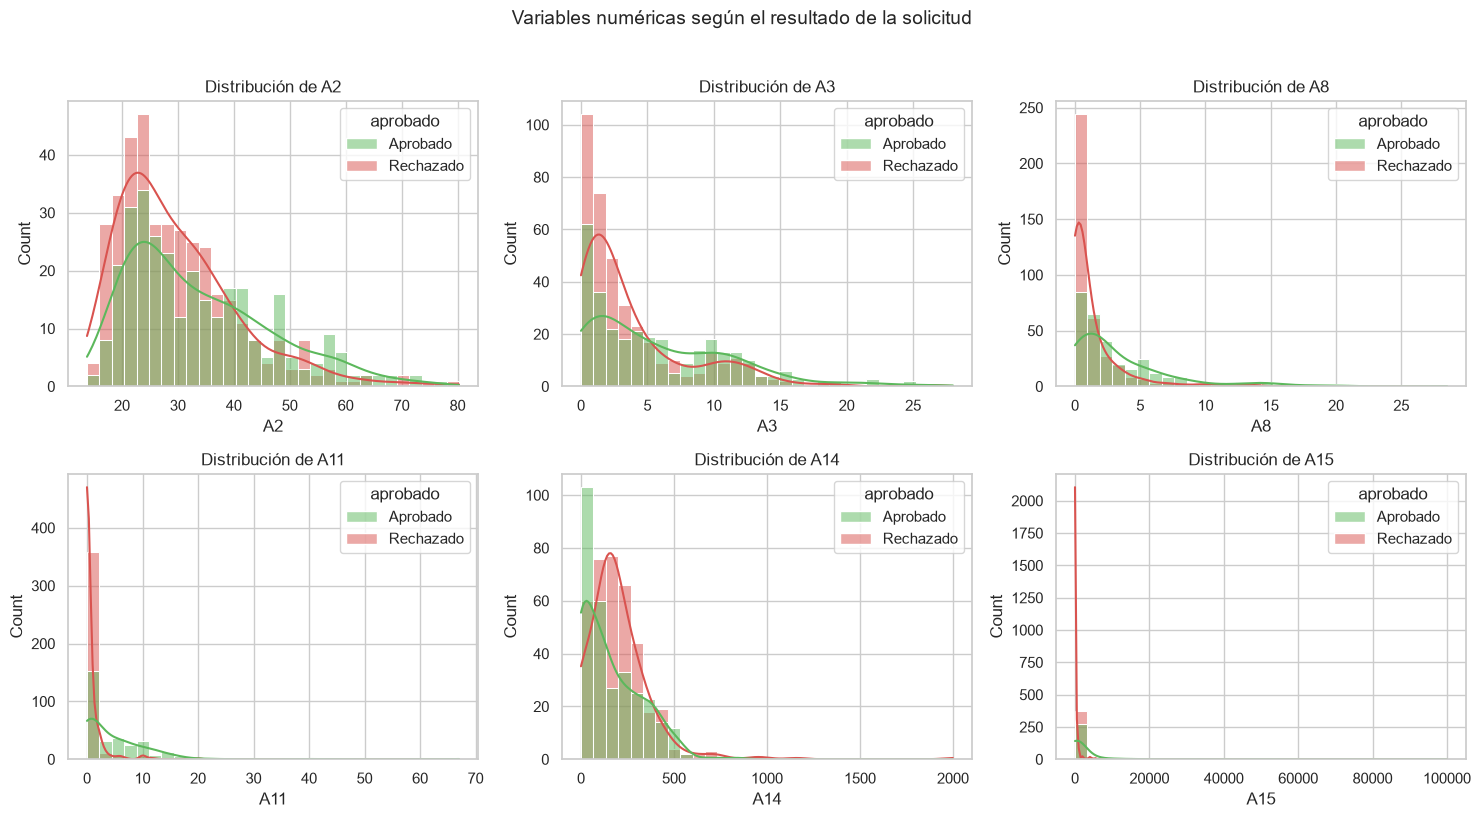

In [7]:
df_eda = X.copy()
df_eda["aprobado"] = y.map({0: "Rechazado", 1: "Aprobado"})

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), cols_num):
    sns.histplot(data=df_eda, x=col, hue="aprobado", kde=True, bins=30,
                 palette={"Rechazado": "#d9534f", "Aprobado": "#5cb85c"}, ax=ax)
    ax.set_title(f"Distribución de {col}")
plt.suptitle("Variables numéricas según el resultado de la solicitud", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

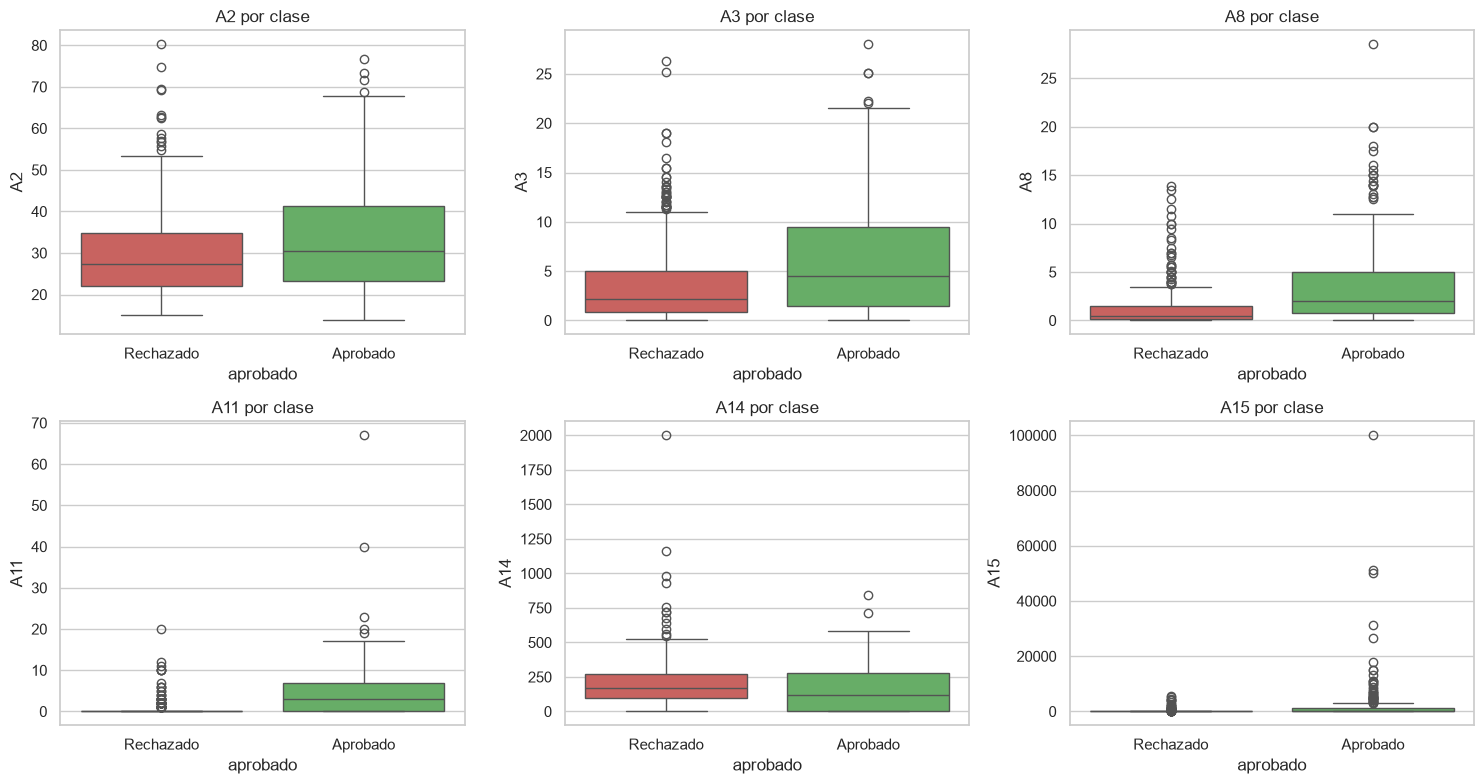

,A2,A3,A8,A11,A14,A15
aprobado,,,,,,
Aprobado,30.50,4.46,2.00,3.0,120.0,221.0
Rechazado,27.33,2.21,0.42,0.0,167.5,1.0


In [8]:
# Boxplots para ver mejor outliers y diferencias entre clases (A3, A8, A11, A14, A15 tienen colas largas)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), cols_num):
    sns.boxplot(data=df_eda, x="aprobado", y=col, order=["Rechazado", "Aprobado"],
                palette={"Rechazado": "#d9534f", "Aprobado": "#5cb85c"}, ax=ax)
    ax.set_title(f"{col} por clase")
plt.tight_layout()
plt.show()

df_eda.groupby("aprobado")[cols_num].median().round(2)

Lo que se observa:

- Casi todas las variables numéricas tienen distribuciones muy sesgadas a la derecha, con muchos valores pequeños y pocos muy grandes (sobre todo `A11`, `A14` y `A15`).
- Las solicitudes aprobadas tienden a tener valores más altos en `A3`, `A8`, `A11` y `A15`. Por ejemplo, la mediana de `A11` es 3 en las aprobadas y 0 en las rechazadas, y la de `A15` es 221 contra 1. Esa diferencia se nota en los boxplots, así que parecen variables informativas. `A14`, en cambio, es algo menor en las aprobadas.
- Existen valores extremos, pero como vamos a usar árboles (que dependen de umbrales y no de la escala) no son un problema grave. Para los modelos que sí son sensibles a la escala (regresión logística, t-SNE) estandarizamos las variables.

### 2.4 Variables categóricas

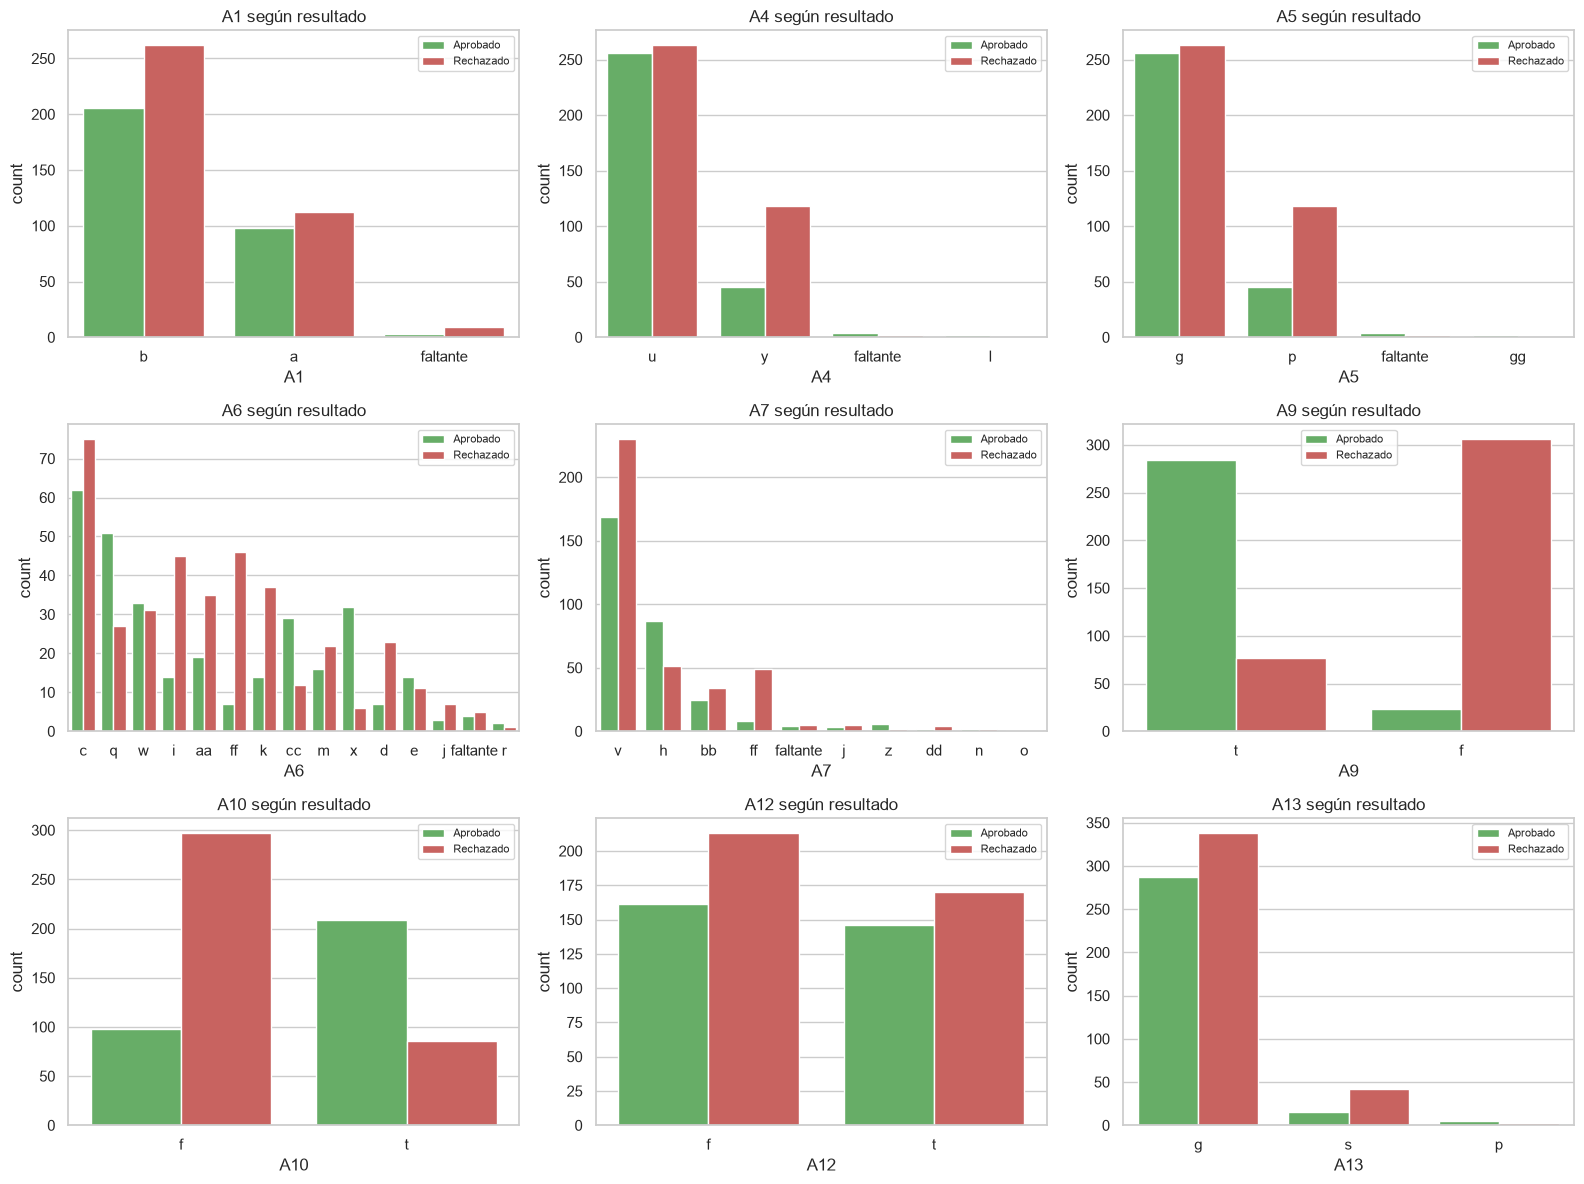

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, col in zip(axes.ravel(), cols_cat):
    orden = df_eda[col].fillna("faltante").value_counts().index
    sns.countplot(data=df_eda.assign(**{col: df_eda[col].fillna("faltante")}),
                  x=col, hue="aprobado", order=orden,
                  palette={"Rechazado": "#d9534f", "Aprobado": "#5cb85c"}, ax=ax)
    ax.set_title(f"{col} según resultado")
    ax.legend(title="", fontsize=8)
plt.tight_layout()
plt.show()

In [10]:
# Tasa de aprobación por categoría en las variables que parecen más discriminantes
for col in ["A9", "A10", "A13"]:
    tasa = df_eda.groupby(col)["aprobado"].apply(lambda s: (s == "Aprobado").mean() * 100).round(1)
    print(f"Porcentaje de aprobación según {col}:")
    print(tasa.to_string(), "\n")

Porcentaje de aprobación según A9:
A9
f     7.0
t    78.7 

Porcentaje de aprobación según A10:
A10
f    24.8
t    70.8 

Porcentaje de aprobación según A13:
A13
g    45.9
p    62.5
s    26.3 



Aquí aparece lo más llamativo del EDA: la variable `A9` separa casi por sí sola las dos clases. Quienes tienen `A9 = t` se aprueban en cerca del 79 % de los casos, mientras que con `A9 = f` solo se aprueba alrededor del 7 %. `A10` también muestra un patrón parecido (71 % contra 25 %). En cambio `A1`, `A12` y `A13` casi no cambian entre clases, y varias categorías de `A6` y `A7` tienen muy pocos casos. Esto nos hace anticipar que un árbol de decisión probablemente use `A9` en la raíz.

### 2.5 Correlación entre variables numéricas

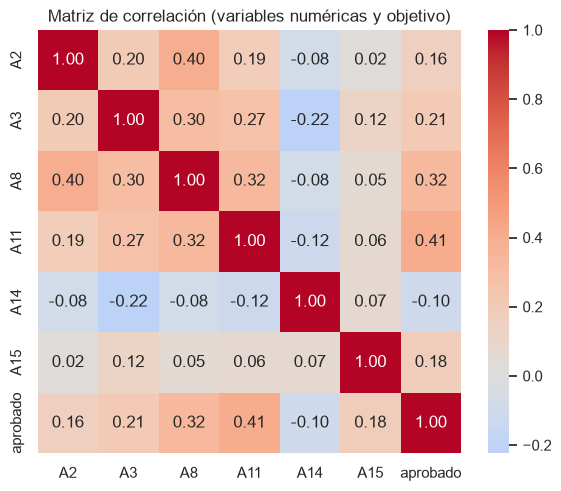

In [11]:
corr = X[cols_num].assign(aprobado=y).corr()

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Matriz de correlación (variables numéricas y objetivo)")
plt.show()

Las correlaciones entre las variables numéricas son bajas o moderadas (la mayor es 0.40, entre `A2` y `A8`), así que no hay un problema fuerte de multicolinealidad. Sobre la variable objetivo, `A11` (0.41) y `A8` (0.32) son las que más se relacionan, aunque ninguna lo hace de forma muy intensa. Esto confirma que el problema no es lineal y sencillo, y que combinar variables numéricas con categóricas (como hace un árbol) tiene sentido.

## 3. Feature extraction y feature selection

### 3.1 Feature extraction

La extracción de características mediante *transfer learning* aplica cuando se trabaja con datos no estructurados (imágenes, texto, audio) y se aprovecha un modelo preentrenado. Nuestro dataset es **tabular y estructurado**, por lo tanto este paso no aplica y lo omitimos. Lo que sí hacemos es transformar las variables (imputar, estandarizar y codificar las categóricas con *one-hot*), y eso va dentro del pipeline de la sección 4.

### 3.2 Feature selection (tipo filtro)

Como técnica de filtro usamos la **información mutua** [4], [5]. Mide cuánta información aporta cada variable sobre el objetivo, sin necesidad de entrenar ningún modelo, y además detecta relaciones no lineales (a diferencia de la correlación). Se implementa con `SelectKBest(mutual_info_classif)`.

Primero hacemos el análisis exploratorio de los puntajes para entender qué variables pesan más. Para evitar fuga de información, separamos antes el conjunto de prueba, que no volvemos a tocar hasta la evaluación final (sección 7).

In [12]:
# Separamos 20 % para prueba final, estratificado para mantener la proporción de clases
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

print(f"Entrenamiento: {X_train.shape[0]} filas | Prueba: {X_test.shape[0]} filas")
print("Proporción de aprobados en entrenamiento:", round(y_train.mean(), 3))
print("Proporción de aprobados en prueba       :", round(y_test.mean(), 3))

Entrenamiento: 552 filas | Prueba: 138 filas
Proporción de aprobados en entrenamiento: 0.446
Proporción de aprobados en prueba       : 0.442


Número de variables después del one-hot: 46


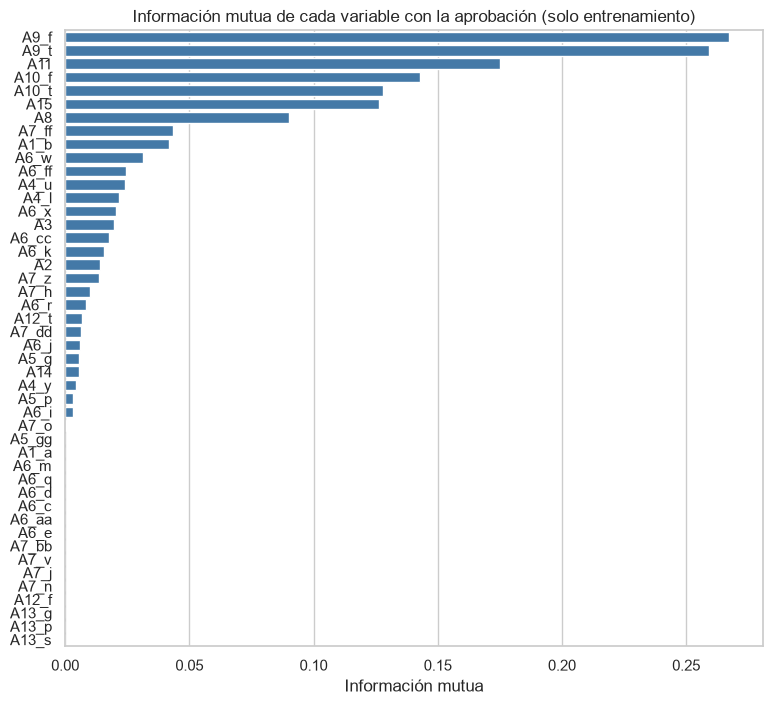

A9_f     0.267
A9_t     0.259
A11      0.175
A10_f    0.143
A10_t    0.128
A15      0.126
A8       0.090
A7_ff    0.044
A1_b     0.042
A6_w     0.031
dtype: float64

In [13]:
# Preprocesamiento: numéricas -> mediana + estandarizar; categóricas -> moda + one-hot
def crear_preprocesador():
    num_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", num_pipe, cols_num),
        ("cat", cat_pipe, cols_cat),
    ])


# Puntaje de información mutua de cada variable (ya codificada) usando SOLO entrenamiento
prep_tmp = crear_preprocesador()
Xtr_prep = prep_tmp.fit_transform(X_train)
nombres = [n.split("__")[1] for n in prep_tmp.get_feature_names_out()]
print("Número de variables después del one-hot:", len(nombres))

mi = mutual_info_classif(Xtr_prep, y_train, random_state=SEED)
mi_df = pd.Series(mi, index=nombres).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 8))
sns.barplot(x=mi_df.values, y=mi_df.index, color="#337ab7", ax=ax)
ax.set_title("Información mutua de cada variable con la aprobación (solo entrenamiento)")
ax.set_xlabel("Información mutua")
ax.set_ylabel("")
plt.show()

mi_df.head(10).round(3)

Los puntajes confirman lo visto en el EDA: las variables derivadas de `A9` (`A9_f`, `A9_t`) dominan claramente. Detrás vienen `A11`, `A10`, `A15` y `A8`. Tras el *one-hot* quedamos con 46 columnas y la mayoría (categorías raras de `A4`, `A5`, `A6`, `A7`, `A13`) tiene puntajes cercanos a cero, así que probablemente solo agregan ruido, lo cual justifica filtrar.

Una pregunta práctica es cuántas variables conservar. En vez de elegir un número a ojo, trataremos **`k` como un hiperparámetro** más del pipeline y lo optimizaremos junto con el resto en la sección 5.

## 4. Pipelines de scikit-learn

Todo el flujo lo encapsulamos en un `Pipeline` con tres etapas:

1. **Preprocesamiento** (`ColumnTransformer`): imputación y escalado o *one-hot* según el tipo de columna.
2. **Selección de variables**: `SelectKBest` con información mutua.
3. **Clasificador**: árbol de decisión, Random Forest, regresión logística o un clasificador base.

La gran ventaja es que cada paso se ajusta únicamente con los datos de entrenamiento de cada *fold* durante la validación cruzada, de modo que no hay fuga de información. Además el código queda ordenado y reutilizable.

In [14]:
# Función de información mutua con semilla fija, para que el pipeline sea reproducible
mi_score = partial(mutual_info_classif, random_state=SEED)


def crear_pipeline(clasificador, k="all"):
    """Arma el pipeline completo: preprocesamiento -> selección (filtro) -> clasificador."""
    return Pipeline([
        ("prep", crear_preprocesador()),
        ("sel", SelectKBest(score_func=mi_score, k=k)),
        ("clf", clasificador),
    ])


pipe_dt = crear_pipeline(DecisionTreeClassifier(random_state=SEED))
pipe_rf = crear_pipeline(RandomForestClassifier(random_state=SEED, n_jobs=-1))
pipe_lr = crear_pipeline(LogisticRegression(max_iter=1000, random_state=SEED))
pipe_dummy = crear_pipeline(DummyClassifier(strategy="most_frequent"))

pipe_dt

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('sel', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the outp

### 4.1 Modelos de referencia (baselines)

Antes de optimizar nada conviene saber de dónde partimos. Evaluamos con validación cruzada repetida (5 folds × 3 repeticiones) sobre el conjunto de entrenamiento: un clasificador que siempre responde la clase mayoritaria, una regresión logística y un árbol de decisión sin ajustar.

In [15]:
# Validación cruzada repetida: 5 folds x 3 repeticiones
cv_base = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

modelos_base = {
    "Dummy (clase mayoritaria)": pipe_dummy,
    "Regresión logística": pipe_lr,
    "Árbol de decisión (sin ajustar)": pipe_dt,
    "Random Forest (sin ajustar)": pipe_rf,
}

filas = []
for nombre, modelo in modelos_base.items():
    scores = cross_val_score(modelo, X_train, y_train, cv=cv_base, scoring="accuracy", n_jobs=-1)
    filas.append({"modelo": nombre, "accuracy medio": scores.mean(), "desv. estándar": scores.std()})

tabla_base = pd.DataFrame(filas).set_index("modelo").round(4)
tabla_base

,accuracy medio,desv. estándar
modelo,,
Dummy (clase mayoritaria),0.5543,0.0029
Regresión logística,0.8442,0.0355
Árbol de decisión (sin ajustar),0.8092,0.0314
Random Forest (sin ajustar),0.8605,0.0306


Los modelos con aprendizaje superan por mucho al clasificador ingenuo (~55 %). La regresión logística llega a cerca de 84 % y el Random Forest sin ajustar a cerca de 86 %. El árbol de decisión sin ajustar es el más flojo (alrededor de 81 %), algo esperable porque un árbol que crece sin límite tiende a memorizar el entrenamiento. Vamos a ver cuánto mejora al ajustar sus hiperparámetros.

## 5. Optimización de hiperparámetros

Usamos `GridSearchCV` con **validación cruzada repetida estratificada** (`RepeatedStratifiedKFold`, 5 folds × 3 repeticiones) sobre el conjunto de entrenamiento. Repetir la validación reduce la varianza de la estimación, algo importante con solo 552 filas de entrenamiento. No usamos *nested* CV porque aumenta mucho el costo de cómputo y no se recomienda para este proyecto.

La métrica de optimización es **accuracy**, porque las clases están balanceadas. Optimizamos en conjunto el número de variables seleccionadas (`k`) y los hiperparámetros del árbol:

| Hiperparámetro | Valores | Qué controla |
|---|---|---|
| `sel__k` | 5, 10, 15, 20, todas | Cuántas variables deja pasar el filtro |
| `clf__max_depth` | 2, 3, 4, 5, 6, 8, sin límite | Profundidad máxima del árbol |
| `clf__min_samples_leaf` | 1, 5, 10, 20 | Mínimo de muestras por hoja |
| `clf__criterion` | gini, entropy | Medida de impureza para dividir |

### 5.1 Árbol de decisión

In [16]:
# Validación cruzada repetida para la búsqueda
cv_opt = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

param_grid_dt = {
    "sel__k": [5, 10, 15, 20, "all"],
    "clf__max_depth": [2, 3, 4, 5, 6, 8, None],
    "clf__min_samples_leaf": [1, 5, 10, 20],
    "clf__criterion": ["gini", "entropy"],
}

grid_dt = GridSearchCV(
    estimator=crear_pipeline(DecisionTreeClassifier(random_state=SEED)),
    param_grid=param_grid_dt,
    scoring="accuracy",
    cv=cv_opt,
    n_jobs=-1,
    refit=True,
)
grid_dt.fit(X_train, y_train)

print("Mejores hiperparámetros del árbol:")
for p, v in grid_dt.best_params_.items():
    print(f"  {p}: {v}")
print(f"\nAccuracy medio en validación (CV repetida): {grid_dt.best_score_:.4f}")

Mejores hiperparámetros del árbol:
  clf__criterion: entropy
  clf__max_depth: 5
  clf__min_samples_leaf: 20
  sel__k: 15

Accuracy medio en validación (CV repetida): 0.8538


In [17]:
# Los 10 mejores resultados de la búsqueda
res_dt = pd.DataFrame(grid_dt.cv_results_)
cols_res = ["param_sel__k", "param_clf__max_depth", "param_clf__min_samples_leaf",
            "param_clf__criterion", "mean_test_score", "std_test_score"]
res_dt.sort_values("rank_test_score")[cols_res].head(10).round(4).reset_index(drop=True)

,param_sel__k,param_clf__max_depth,param_clf__min_samples_leaf,param_clf__criterion,mean_test_score,std_test_score
0,15,None,20,entropy,0.8538,0.0335
1,15,8,20,entropy,0.8538,0.0335
2,15,6,20,entropy,0.8538,0.0335
3,15,5,20,entropy,0.8538,0.0335
4,20,4,20,gini,0.8514,0.0309
5,20,None,20,gini,0.8514,0.0309
6,20,6,20,gini,0.8514,0.0309
7,20,5,20,gini,0.8514,0.0309
8,20,8,20,gini,0.8514,0.0309
9,20,None,20,entropy,0.8514,0.0329


### 5.2 Gráfica de optimización de un hiperparámetro

Para ver el efecto de los hiperparámetros más importantes usamos `validation_curve`, fijando el resto en sus mejores valores. Cada curva compara el accuracy en entrenamiento contra el de validación (con su desviación estándar sobre las 15 particiones). Es la forma clásica de ver el compromiso entre sesgo y varianza. Hacemos dos gráficas:

- **Panel A:** profundidad máxima (`max_depth`), con `min_samples_leaf = 1` para que el árbol pueda crecer libremente y se vea bien el efecto de la profundidad por sí sola.
- **Panel B:** mínimo de muestras por hoja (`min_samples_leaf`), con la profundidad en su mejor valor.

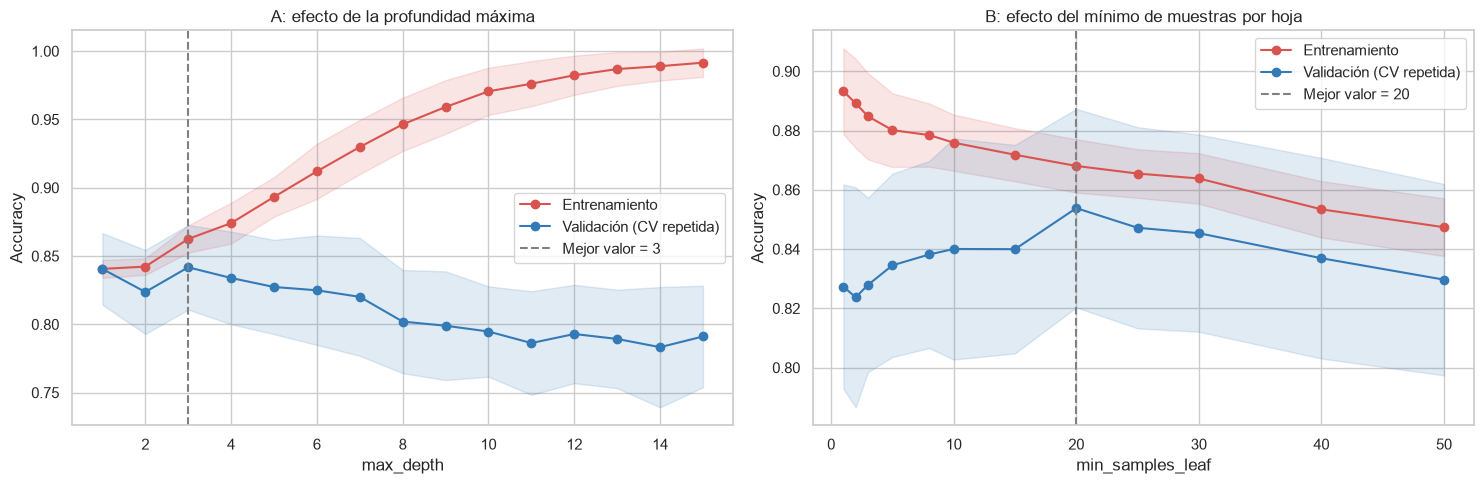

Panel A: mejor max_depth = 3 (accuracy de validación 0.8417)
Panel B: mejor min_samples_leaf = 20 (accuracy de validación 0.8538)
Accuracy de entrenamiento con max_depth=15: 0.9915


In [18]:
mejores = grid_dt.best_params_


def pipeline_arbol(**kwargs):
    # Árbol con el criterio y el k óptimos, variando solo lo que pasemos por kwargs
    return crear_pipeline(
        DecisionTreeClassifier(random_state=SEED, criterion=mejores["clf__criterion"], **kwargs),
        k=mejores["sel__k"],
    )


def graficar_validacion(ax, rango, train_sc, val_sc, nombre, titulo):
    tr_m, tr_s = train_sc.mean(axis=1), train_sc.std(axis=1)
    va_m, va_s = val_sc.mean(axis=1), val_sc.std(axis=1)
    mejor = rango[va_m.argmax()]
    ax.plot(rango, tr_m, "o-", color="#d9534f", label="Entrenamiento")
    ax.fill_between(rango, tr_m - tr_s, tr_m + tr_s, color="#d9534f", alpha=0.15)
    ax.plot(rango, va_m, "o-", color="#337ab7", label="Validación (CV repetida)")
    ax.fill_between(rango, va_m - va_s, va_m + va_s, color="#337ab7", alpha=0.15)
    ax.axvline(mejor, color="gray", ls="--", label=f"Mejor valor = {mejor}")
    ax.set_xlabel(nombre)
    ax.set_ylabel("Accuracy")
    ax.set_title(titulo)
    ax.legend()
    return mejor, va_m.max()


fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Panel A: profundidad máxima (hojas sin restricción)
profundidades = np.arange(1, 16)
tr_a, va_a = validation_curve(
    pipeline_arbol(min_samples_leaf=1), X_train, y_train,
    param_name="clf__max_depth", param_range=profundidades,
    cv=cv_opt, scoring="accuracy", n_jobs=-1)
mejor_a, acc_a = graficar_validacion(axes[0], profundidades, tr_a, va_a, "max_depth",
                                     "A: efecto de la profundidad máxima")

# Panel B: mínimo de muestras por hoja (profundidad óptima)
minimos = np.array([1, 2, 3, 5, 8, 10, 15, 20, 25, 30, 40, 50])
tr_b, va_b = validation_curve(
    pipeline_arbol(max_depth=mejores["clf__max_depth"]), X_train, y_train,
    param_name="clf__min_samples_leaf", param_range=minimos,
    cv=cv_opt, scoring="accuracy", n_jobs=-1)
mejor_b, acc_b = graficar_validacion(axes[1], minimos, tr_b, va_b, "min_samples_leaf",
                                     "B: efecto del mínimo de muestras por hoja")

plt.tight_layout()
plt.show()

print(f"Panel A: mejor max_depth = {mejor_a} (accuracy de validación {acc_a:.4f})")
print(f"Panel B: mejor min_samples_leaf = {mejor_b} (accuracy de validación {acc_b:.4f})")
print(f"Accuracy de entrenamiento con max_depth=15: {tr_a.mean(axis=1)[-1]:.4f}")

**Panel A.** Es el caso clásico de sobreajuste. El accuracy de entrenamiento sube de 0.84 hasta casi 0.99 al aumentar la profundidad, mientras que el de validación baja de 0.84 a cerca de 0.79: el árbol memoriza el entrenamiento y generaliza peor. Con hojas sin restricción, la mejor profundidad es 3.

**Panel B.** Exigir más muestras por hoja funciona como regularización. Con valores pequeños hay mucha brecha entre entrenamiento y validación, y esa brecha se reduce al subir el mínimo. El mejor valor en validación es 20 (accuracy ≈ 0.854), que coincide con lo que eligió la búsqueda en malla. Si se pide más de 20 el árbol se vuelve demasiado simple y ambas curvas bajan (subajuste).

Un detalle que explica la tabla de resultados de la sección 5.1: con `min_samples_leaf = 20` el árbol ya no puede crecer mucho, por lo que valores de `max_depth` de 5, 6, 8 o sin límite dan exactamente el mismo resultado. Fue entonces `min_samples_leaf` el hiperparámetro que realmente controló la complejidad.

### 5.3 Curva de aprendizaje

Con el árbol ya optimizado, dibujamos la curva de aprendizaje: cómo cambia el desempeño al aumentar la cantidad de datos de entrenamiento. Nos dice si más datos ayudarían o si el modelo ya se estabilizó.

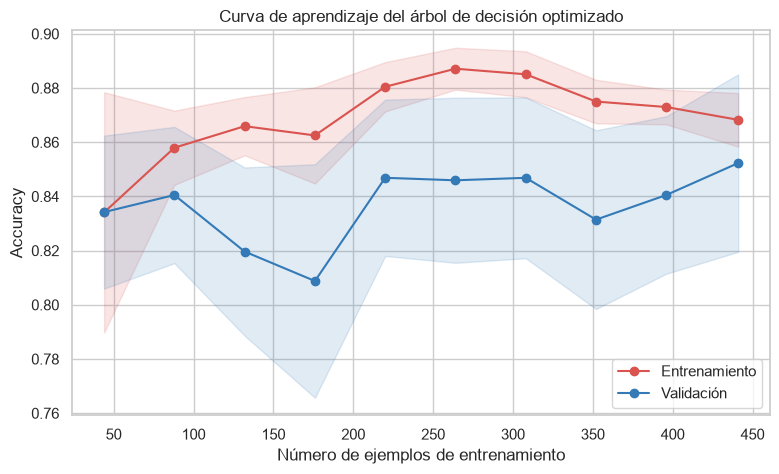

In [19]:
mejor_dt = grid_dt.best_estimator_
cv_lc = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)

tam, tr_lc, va_lc = learning_curve(
    mejor_dt, X_train, y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=cv_lc, scoring="accuracy", n_jobs=-1, random_state=SEED,
)

plt.figure(figsize=(9, 5))
plt.plot(tam, tr_lc.mean(axis=1), "o-", color="#d9534f", label="Entrenamiento")
plt.fill_between(tam, tr_lc.mean(axis=1) - tr_lc.std(axis=1),
                 tr_lc.mean(axis=1) + tr_lc.std(axis=1), color="#d9534f", alpha=0.15)
plt.plot(tam, va_lc.mean(axis=1), "o-", color="#337ab7", label="Validación")
plt.fill_between(tam, va_lc.mean(axis=1) - va_lc.std(axis=1),
                 va_lc.mean(axis=1) + va_lc.std(axis=1), color="#337ab7", alpha=0.15)
plt.xlabel("Número de ejemplos de entrenamiento")
plt.ylabel("Accuracy")
plt.title("Curva de aprendizaje del árbol de decisión optimizado")
plt.legend(loc="lower right")
plt.show()

Con pocos datos el modelo rinde peor en validación y las bandas de desviación son muy anchas, es decir, la estimación es inestable. A medida que se agregan ejemplos el accuracy de validación sube hasta cerca de 0.85 y la brecha con el entrenamiento (≈ 0.87) se reduce a unos 1.5 puntos, lo que indica que el árbol optimizado no está sobreajustado. La curva de validación todavía sube un poco al final, por lo que más datos probablemente darían una mejora modesta, no un salto grande.

### 5.4 Random Forest

Para la comparación estadística de la siguiente sección necesitamos también el segundo modelo con sus hiperparámetros optimizados bajo el mismo esquema de validación. Usamos una malla más pequeña porque el Random Forest es más costoso de entrenar.

In [20]:
param_grid_rf = {
    "sel__k": [10, "all"],
    "clf__max_depth": [3, 5, None],
    "clf__min_samples_leaf": [1, 3, 5],
    "clf__max_features": ["sqrt", 0.5],
}

grid_rf = GridSearchCV(
    estimator=crear_pipeline(RandomForestClassifier(n_estimators=300, random_state=SEED)),
    param_grid=param_grid_rf,
    scoring="accuracy",
    cv=cv_opt,
    n_jobs=-1,
    refit=True,
)
grid_rf.fit(X_train, y_train)

print("Mejores hiperparámetros del Random Forest:")
for p, v in grid_rf.best_params_.items():
    print(f"  {p}: {v}")
print(f"\nAccuracy medio en validación (CV repetida): {grid_rf.best_score_:.4f}")

Mejores hiperparámetros del Random Forest:
  clf__max_depth: 3
  clf__max_features: sqrt
  clf__min_samples_leaf: 5
  sel__k: all

Accuracy medio en validación (CV repetida): 0.8665


## 6. Comparación estadística entre dos técnicas de ML

Quedarnos con que un modelo tiene 0.5 puntos más de accuracy que otro no es suficiente: con tan pocos datos esa diferencia podría deberse al azar de la partición. Por eso hacemos un **test de hipótesis**.

**Modelos comparados:** árbol de decisión optimizado vs. Random Forest optimizado.

**Procedimiento:**
- Validación cruzada repetida estratificada con **10 repeticiones × 10 folds** (100 puntajes por modelo), sobre el conjunto de entrenamiento.
- Ambos modelos se evalúan con **exactamente las mismas particiones**, así las muestras son pareadas.
- Test de **Wilcoxon de rangos con signo** [6], recomendado por Demšar [7] para comparar clasificadores porque no asume normalidad de las diferencias.

**Hipótesis:**
- H0: no hay diferencia en el accuracy entre ambos modelos.
- H1: sí hay diferencia (prueba bilateral).
- Nivel de significancia: α = 0.05.

In [21]:
# 10 repeticiones x 10 folds, mismas particiones para ambos modelos (misma semilla)
cv_stat = RepeatedStratifiedKFold(n_splits=10, n_repeats=10, random_state=SEED)

scores_dt = cross_val_score(grid_dt.best_estimator_, X_train, y_train,
                            cv=cv_stat, scoring="accuracy", n_jobs=-1)
scores_rf = cross_val_score(grid_rf.best_estimator_, X_train, y_train,
                            cv=cv_stat, scoring="accuracy", n_jobs=-1)

print(f"Árbol de decisión : {scores_dt.mean():.4f} ± {scores_dt.std():.4f}")
print(f"Random Forest     : {scores_rf.mean():.4f} ± {scores_rf.std():.4f}")
print(f"Diferencia media (RF - DT): {(scores_rf - scores_dt).mean():.4f}")

Árbol de decisión : 0.8502 ± 0.0467
Random Forest     : 0.8639 ± 0.0506
Diferencia media (RF - DT): 0.0138


In [22]:
# Test de Wilcoxon pareado (bilateral)
stat_w, p_w = stats.wilcoxon(scores_dt, scores_rf, alternative="two-sided")

print("Test de Wilcoxon (pareado, bilateral)")
print(f"  Estadístico = {stat_w:.2f}")
print(f"  p-valor     = {p_w:.6f}")

alpha = 0.05
if p_w < alpha:
    print(f"\n  p < {alpha}: se rechaza H0, la diferencia es estadísticamente significativa.")
else:
    print(f"\n  p >= {alpha}: no se rechaza H0, no hay evidencia suficiente de que los modelos difieran.")

Test de Wilcoxon (pareado, bilateral)
  Estadístico = 1061.00
  p-valor     = 0.000179

  p < 0.05: se rechaza H0, la diferencia es estadísticamente significativa.


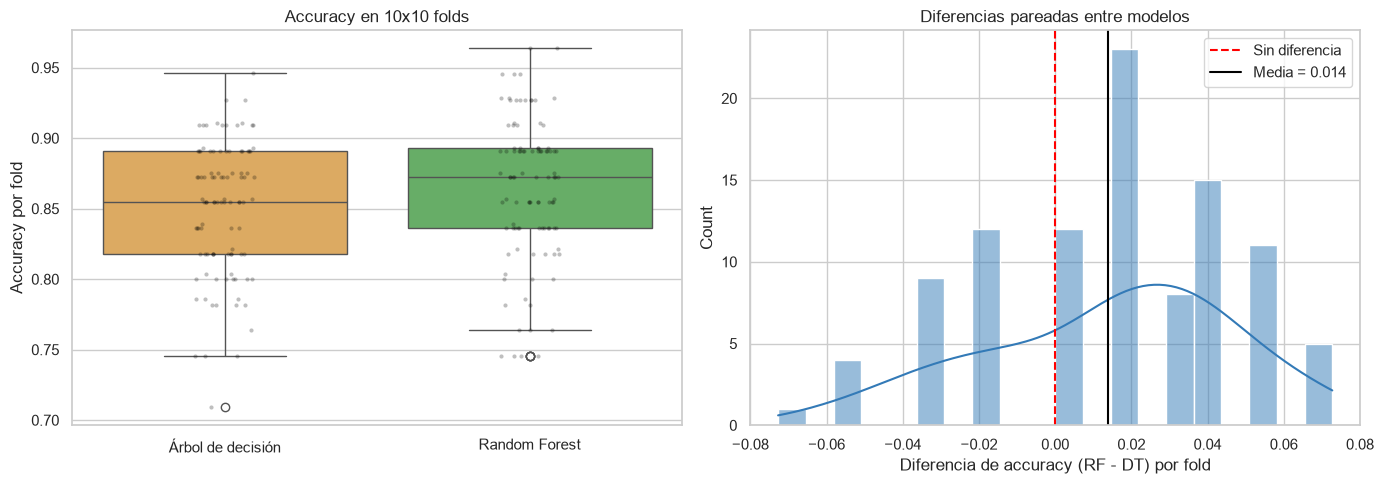

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribución de los 100 puntajes de cada modelo
datos_box = pd.DataFrame({"Árbol de decisión": scores_dt, "Random Forest": scores_rf})
sns.boxplot(data=datos_box, palette=["#f0ad4e", "#5cb85c"], ax=axes[0])
sns.stripplot(data=datos_box, color="black", alpha=0.25, size=3, ax=axes[0])
axes[0].set_ylabel("Accuracy por fold")
axes[0].set_title("Accuracy en 10x10 folds")

# Distribución de las diferencias pareadas
dif = scores_rf - scores_dt
sns.histplot(dif, bins=20, kde=True, color="#337ab7", ax=axes[1])
axes[1].axvline(0, color="red", ls="--", label="Sin diferencia")
axes[1].axvline(dif.mean(), color="black", ls="-", label=f"Media = {dif.mean():.3f}")
axes[1].set_xlabel("Diferencia de accuracy (RF - DT) por fold")
axes[1].set_title("Diferencias pareadas entre modelos")
axes[1].legend()

plt.tight_layout()
plt.show()

**Interpretación:** el Random Forest obtuvo en promedio 1.4 puntos más de accuracy que el árbol (0.864 contra 0.850) y el test de Wilcoxon dio un p-valor de aproximadamente 0.0002, muy por debajo de 0.05. Por lo tanto rechazamos H0: la diferencia es estadísticamente significativa. Aun así, el histograma muestra que la diferencia por fold es pequeña y variable (en muchos folds incluso gana el árbol), así que la ventaja es real pero modesta. Hay que tener presente una limitación: los puntajes de la validación cruzada repetida no son completamente independientes (los conjuntos de entrenamiento se solapan), por lo que el test tiende a ser algo optimista y el p-valor debe leerse con cautela [7], [8]. Por eso complementamos la decisión con el tamaño de la diferencia y no solo con el p-valor.

## 7. Evaluación final sobre el conjunto de prueba

Hasta ahora nunca tocamos el 20 % reservado. Con los modelos ya optimizados, evaluamos una sola vez sobre ese conjunto para tener una estimación honesta de cómo se comportarían con solicitudes nuevas. Incluimos los modelos de referencia para dimensionar las mejoras.

In [24]:
# Entrenamos los baselines con todo el conjunto de entrenamiento
pipe_lr.fit(X_train, y_train)
pipe_dummy.fit(X_train, y_train)

modelos_finales = {
    "Dummy (clase mayoritaria)": pipe_dummy,
    "Regresión logística": pipe_lr,
    "Árbol de decisión (optimizado)": grid_dt.best_estimator_,
    "Random Forest (optimizado)": grid_rf.best_estimator_,
}

filas = []
for nombre, modelo in modelos_finales.items():
    pred = modelo.predict(X_test)
    proba = modelo.predict_proba(X_test)[:, 1]
    filas.append({
        "modelo": nombre,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "AUC-ROC": roc_auc_score(y_test, proba),
    })

tabla_final = pd.DataFrame(filas).set_index("modelo").round(4)
tabla_final

,accuracy,precision,recall,F1,AUC-ROC
modelo,,,,,
Dummy (clase mayoritaria),0.5580,0.0000,0.0000,0.0000,0.5000
Regresión logística,0.8696,0.8525,0.8525,0.8525,0.9602
Árbol de decisión (optimizado),0.8841,0.8571,0.8852,0.8710,0.9493
Random Forest (optimizado),0.8841,0.9412,0.7869,0.8571,0.9593


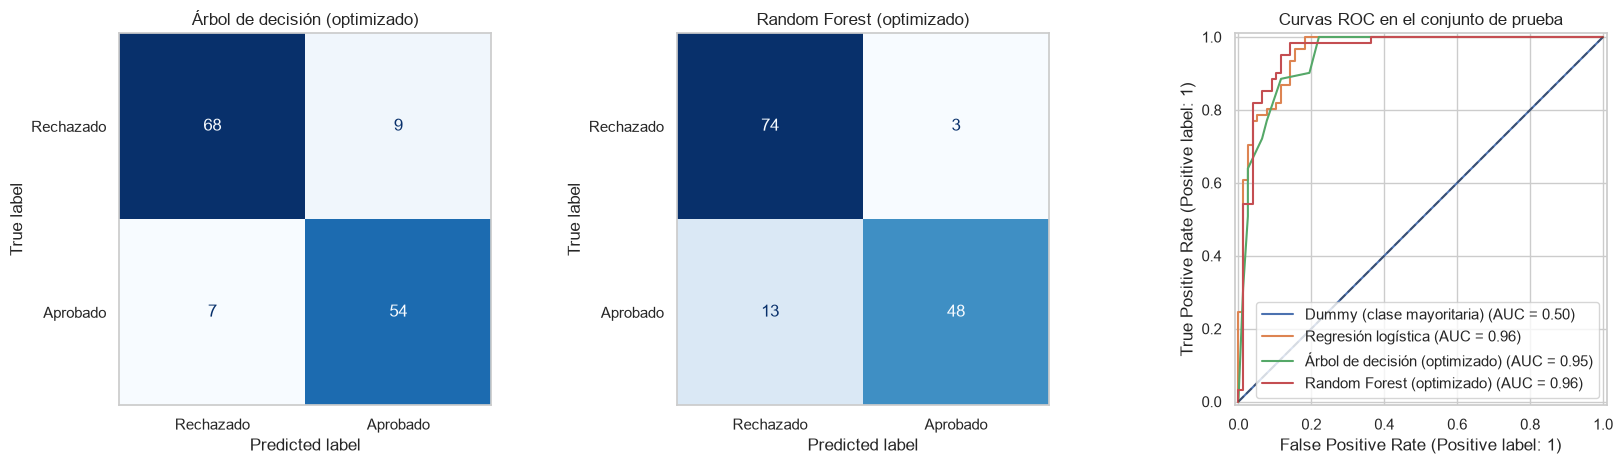

In [25]:
# Matrices de confusión y curvas ROC de los dos modelos principales
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

for ax, (nombre, modelo) in zip(axes[:2], list(modelos_finales.items())[2:]):
    ConfusionMatrixDisplay.from_estimator(
        modelo, X_test, y_test, display_labels=["Rechazado", "Aprobado"],
        cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(nombre)
    ax.grid(False)

for nombre, modelo in modelos_finales.items():
    RocCurveDisplay.from_estimator(modelo, X_test, y_test, name=nombre, ax=axes[2])
axes[2].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[2].set_title("Curvas ROC en el conjunto de prueba")

plt.tight_layout()
plt.show()

En el conjunto de prueba (138 solicitudes) el árbol y el Random Forest empatan en accuracy (0.884), y ambos superan a la regresión logística (0.870) y por mucho al clasificador ingenuo (0.558). La diferencia está en cómo se equivocan: el árbol tiene mayor *recall* (0.885: detecta más solicitudes que sí se aprobaron) y el Random Forest mayor *precision* (0.941: cuando dice que aprueba, casi siempre acierta, pero deja pasar más casos buenos). La regresión logística y el Random Forest tienen el mejor AUC-ROC (≈ 0.96, prácticamente iguales) y el árbol queda algo por debajo (0.949), así que en ranking de probabilidades los tres modelos son parecidos. Con solo 138 casos, una diferencia de una o dos solicitudes mueve el accuracy cerca de 1 punto, por lo que estas diferencias en prueba no son concluyentes por sí solas y la comparación estadística de la sección 6 es más confiable.

### 7.1 Interpretación del árbol de decisión

La principal razón para elegir un árbol es poder leerlo. Graficamos el árbol optimizado y la importancia de las variables que realmente usa.

Variables que pasaron el filtro: 15 de 46
Profundidad real del árbol: 5 | Hojas: 14


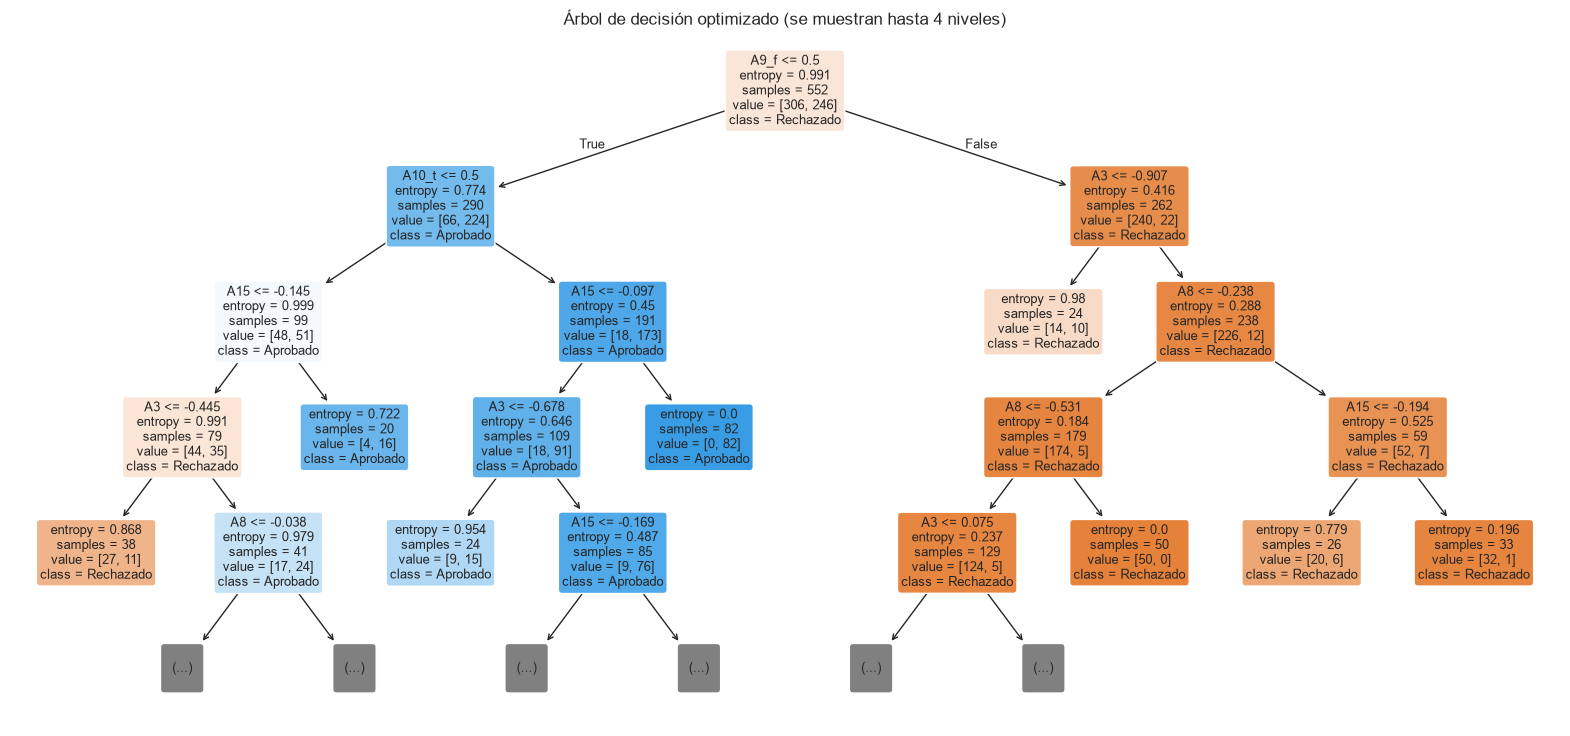

In [26]:
# Recuperamos el árbol y los nombres de las variables que sobrevivieron al filtro
arbol = grid_dt.best_estimator_.named_steps["clf"]
prep_f = grid_dt.best_estimator_.named_steps["prep"]
sel_f = grid_dt.best_estimator_.named_steps["sel"]

nombres_todos = np.array([n.split("__")[1] for n in prep_f.get_feature_names_out()])
nombres_sel = nombres_todos[sel_f.get_support()]

print(f"Variables que pasaron el filtro: {len(nombres_sel)} de {len(nombres_todos)}")
print("Profundidad real del árbol:", arbol.get_depth(), "| Hojas:", arbol.get_n_leaves())

plt.figure(figsize=(20, 9))
plot_tree(arbol, feature_names=nombres_sel, class_names=["Rechazado", "Aprobado"],
          filled=True, rounded=True, fontsize=9, max_depth=4)
plt.title("Árbol de decisión optimizado (se muestran hasta 4 niveles)")
plt.show()

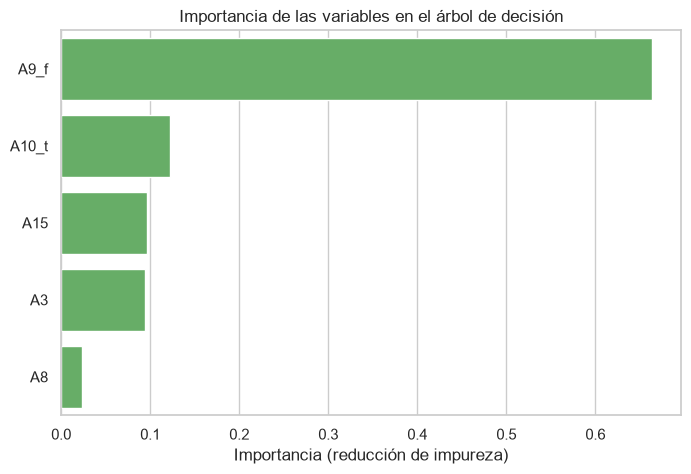

In [27]:
imp = pd.Series(arbol.feature_importances_, index=nombres_sel).sort_values(ascending=False)
imp = imp[imp > 0]

plt.figure(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index, color="#5cb85c")
plt.title("Importancia de las variables en el árbol de decisión")
plt.xlabel("Importancia (reducción de impureza)")
plt.ylabel("")
plt.show()

El árbol queda con 14 hojas y usa solo cinco variables: `A9_f`, `A10_t`, `A15`, `A3` y `A8`. La raíz pregunta por `A9`, y esa variable concentra por lejos la mayor importancia, algo que ya anticipaban el EDA y el filtro de información mutua. Que tres técnicas distintas lleguen a la misma conclusión le da bastante solidez al hallazgo. Si `A9 = f` la rama termina casi siempre en rechazo (nodo de 238 solicitudes con apenas 12 aprobadas), y cuando `A9 = t` entran `A10`, `A15` y `A3` para afinar la decisión. Nótese que las variables numéricas se ven estandarizadas, por eso los umbrales del gráfico son valores como -0.145 y no montos reales. `A11` tenía mucha información mutua pero el árbol no la usa; probablemente porque está relacionada con `A9` y `A10` y no aporta nada nuevo una vez que estas ya dividieron los datos.

## 8. Visualización con t-SNE

t-SNE [9] proyecta datos de alta dimensión a 2D conservando las vecindades locales. Lo usamos para ver si las dos clases forman grupos separables en el espacio de características. Como este caso es **supervisado**, usamos la etiqueta real como color de cada punto. Hacemos dos proyecciones: con todas las variables preprocesadas y solo con las seleccionadas por el filtro.

Esta visualización es exploratoria y no alimenta ningún modelo, por eso se puede ajustar el preprocesamiento sobre las 690 filas sin que afecte la evaluación.

Dimensión con todas las variables  : (690, 46)
Dimensión con las variables filtradas: (690, 15)


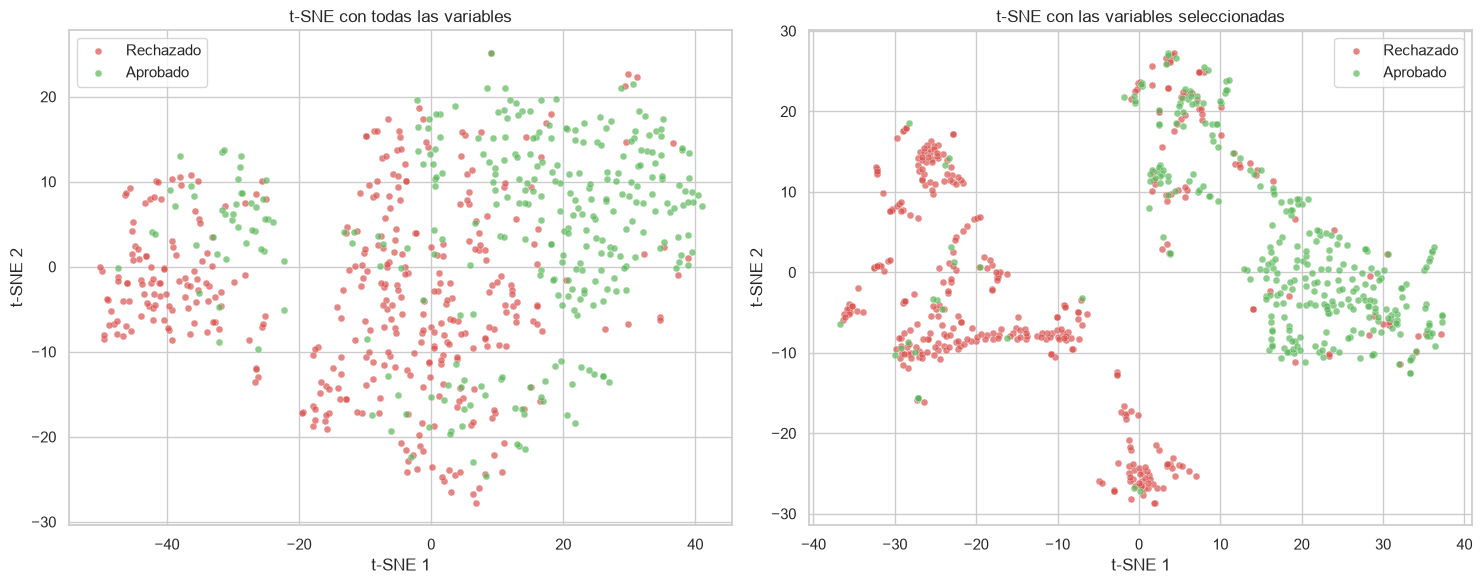

In [28]:
# Datos completos preprocesados (todas las variables) y solo con las seleccionadas por el filtro
prep_viz = crear_preprocesador().fit(X)
X_todas = prep_viz.transform(X)

sel_viz = SelectKBest(score_func=mi_score, k=grid_dt.best_params_["sel__k"]).fit(X_todas, y)
X_selec = sel_viz.transform(X_todas)

print("Dimensión con todas las variables  :", X_todas.shape)
print("Dimensión con las variables filtradas:", X_selec.shape)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
colores = {0: "#d9534f", 1: "#5cb85c"}
nombres_clase = {0: "Rechazado", 1: "Aprobado"}

for ax, datos, titulo in zip(axes, [X_todas, X_selec],
                             ["t-SNE con todas las variables", "t-SNE con las variables seleccionadas"]):
    emb = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto",
               random_state=SEED).fit_transform(datos)
    for clase in [0, 1]:
        m = (y.values == clase)
        ax.scatter(emb[m, 0], emb[m, 1], c=colores[clase], label=nombres_clase[clase],
                   alpha=0.7, s=25, edgecolor="white", linewidth=0.3)
    ax.set_title(titulo)
    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")
    ax.legend()

plt.tight_layout()
plt.show()

Con todas las variables se ven zonas dominadas por cada clase, pero con bastante mezcla en el centro, porque las columnas poco informativas añaden ruido a las distancias. Al quedarnos solo con las variables que pasaron el filtro, los grupos se ven más definidos y la frontera entre aprobados y rechazados es más clara. Es una evidencia visual a favor de la selección de variables. Esta cierta separabilidad también explica por qué incluso un árbol sencillo logra un buen accuracy. Aun así quedan puntos mezclados, que son los casos donde cualquier modelo se equivoca.

## 9. Conclusiones

Después de recorrer todo el flujo de trabajo, estas son las conclusiones principales del proyecto.

**Sobre el problema y los datos.** Pudimos predecir con buena exactitud si una solicitud de crédito fue aprobada o rechazada, pese a que las variables están anonimizadas y a que el dataset es pequeño (690 filas). Un clasificador que siempre responde la clase mayoritaria acierta cerca del 56 %, y nuestros modelos finales llegan a cerca del 88 % en el conjunto de prueba, así que el aprendizaje de máquina sí aporta valor real frente a no hacer nada.

**Sobre las variables.** Todo apunta a que `A9` es el factor que más pesa en la decisión. Lo vimos en el EDA (la tasa de aprobación pasa de 7 % a 79 % según su valor), lo confirmó el filtro de información mutua y es la raíz del árbol final. Le siguen `A10`, `A15`, `A3` y `A8`. El filtro de información mutua nos permitió quedarnos con 15 de las 46 columnas generadas sin perder rendimiento, y el t-SNE mostró que con esas variables los grupos de aprobados y rechazados quedan más separados que con todas. Como las variables son anónimas, no podemos decir qué significan en términos de negocio, y esto es una limitación importante para explicar el modelo ante una persona real.

**Sobre la optimización.** Los resultados mostraron que el hiperparámetro que más pesó en el árbol fue el mínimo de muestras por hoja (20 fue el mejor valor), más que la profundidad máxima. Un árbol sin restricciones llegó a casi 99 % de accuracy en entrenamiento pero cayó a cerca de 79 % en validación, es decir, se sobreajusta con claridad. Al regularizarlo, la validación subió a cerca de 85 % y la brecha con el entrenamiento se redujo a un par de puntos. La curva de aprendizaje sugiere que conseguir más datos ayudaría algo, pero no de forma espectacular.

**Sobre la comparación entre modelos.** El test de Wilcoxon con 10 repeticiones de 10 folds indicó que el Random Forest es mejor que el árbol de decisión de forma estadísticamente significativa (p ≈ 0.0002), aunque la ventaja media es pequeña, de alrededor de 1.4 puntos de accuracy. En el conjunto de prueba ambos terminaron empatados en accuracy (0.884), con perfiles distintos: el árbol detecta más aprobaciones (recall 0.885) y el Random Forest se equivoca menos al aprobar (precision 0.941). La regresión logística, que es un modelo mucho más simple, quedó apenas por debajo (0.870), lo cual nos dice que el problema es en buena medida separable con relaciones sencillas.

**Qué modelo elegiríamos.** Para este problema nos quedaríamos con el árbol de decisión optimizado si lo más importante es explicar cada decisión, porque rinde casi igual que el Random Forest y se puede leer completo con solo cinco variables. Si lo que importa es evitar aprobar a quien no va a pagar, el Random Forest es más conveniente por su mayor precisión. La elección depende entonces del costo de cada tipo de error, y eso es algo que el banco tendría que definir.

**Limitaciones.**
- El dataset es pequeño, por lo que las estimaciones tienen bastante variabilidad (las desviaciones en validación cruzada rondan los 3 a 5 puntos) y el conjunto de prueba de 138 casos solo permite diferencias gruesas entre modelos.
- La validación cruzada repetida genera puntajes que no son independientes, así que el p-valor del test de Wilcoxon es algo optimista.
- Usamos accuracy como métrica de optimización porque las clases están balanceadas, pero en un caso real los errores no cuestan lo mismo y convendría una métrica ponderada por costo.
- Al ser variables anónimas no pudimos revisar sesgos ni validar si el modelo usa información que no debería usarse para decidir sobre una persona.

**Trabajo futuro.** Se podría probar optimización con Optuna, otros modelos como gradient boosting o SVM, calibración de probabilidades para elegir el umbral de decisión según el costo de cada error, y un esquema de validación anidada para confirmar que la estimación final no está sesgada por la optimización.

## 10. Referencias

[1] J. R. Quinlan, "Credit Approval," UCI Machine Learning Repository, 1987. [En línea]. Disponible: https://doi.org/10.24432/C5FS30

[2] L. Breiman, J. Friedman, R. A. Olshen y C. J. Stone, *Classification and Regression Trees*. Belmont, CA, EE. UU.: Wadsworth, 1984.

[3] L. Breiman, "Random forests," *Machine Learning*, vol. 45, n.º 1, pp. 5–32, 2001.

[4] A. Kraskov, H. Stögbauer y P. Grassberger, "Estimating mutual information," *Physical Review E*, vol. 69, n.º 6, art. 066138, 2004.

[5] B. C. Ross, "Mutual information between discrete and continuous data sets," *PLoS ONE*, vol. 9, n.º 2, art. e87357, 2014.

[6] F. Wilcoxon, "Individual comparisons by ranking methods," *Biometrics Bulletin*, vol. 1, n.º 6, pp. 80–83, 1945.

[7] J. Demšar, "Statistical comparisons of classifiers over multiple data sets," *Journal of Machine Learning Research*, vol. 7, pp. 1–30, 2006.

[8] C. Nadeau y Y. Bengio, "Inference for the generalization error," *Machine Learning*, vol. 52, n.º 3, pp. 239–281, 2003.

[9] L. van der Maaten y G. Hinton, "Visualizing data using t-SNE," *Journal of Machine Learning Research*, vol. 9, pp. 2579–2605, 2008.

[10] F. Pedregosa *et al.*, "Scikit-learn: Machine learning in Python," *Journal of Machine Learning Research*, vol. 12, pp. 2825–2830, 2011.

[11] Material de clase (presentaciones y notebooks) de la materia Aprendizaje de Máquina, programa de maestría, 2026.